# Projet prediction du churn (bank customer churn)

In [54]:
# import de données: Bank Customer Churn Modelling from: https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling
#Cet ensemble de données contient des informations sur les clients d'une banque, 
#et la variable cible est une variable binaire indiquant si le client a quitté la banque (fermé son compte) 
#ou s'il continue d'être client.

import pandas as pd

df = pd.read_csv("C:/Users/angou/Desktop/Formation python/Churn.csv")
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


| Variable        | Description           |
| --------------- | --------------------- |
| CreditScore     | score de crédit       |
| Geography       | pays                  |
| Gender          | sexe                  |
| Age             | âge                   |
| Tenure          | ancienneté            |
| Balance         | solde                 |
| NumOfProducts   | nb de produits        |
| HasCrCard       | carte bancaire        |
| IsActiveMember  | activité              |
| EstimatedSalary | salaire               |
| Exited          | target (1 = churn) |


Supprime les colonnes inutiles :

In [55]:
df = df.drop(["RowNumber", "CustomerId", "Surname"], axis=1)

In [56]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


# EDA

In [57]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      10000 non-null  int64  
 1   Geography        10000 non-null  str    
 2   Gender           10000 non-null  str    
 3   Age              10000 non-null  int64  
 4   Tenure           10000 non-null  int64  
 5   Balance          10000 non-null  float64
 6   NumOfProducts    10000 non-null  int64  
 7   HasCrCard        10000 non-null  int64  
 8   IsActiveMember   10000 non-null  int64  
 9   EstimatedSalary  10000 non-null  float64
 10  Exited           10000 non-null  int64  
dtypes: float64(2), int64(7), str(2)
memory usage: 859.5 KB


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


un base de données de 10.000 lignes et 11 colonnes

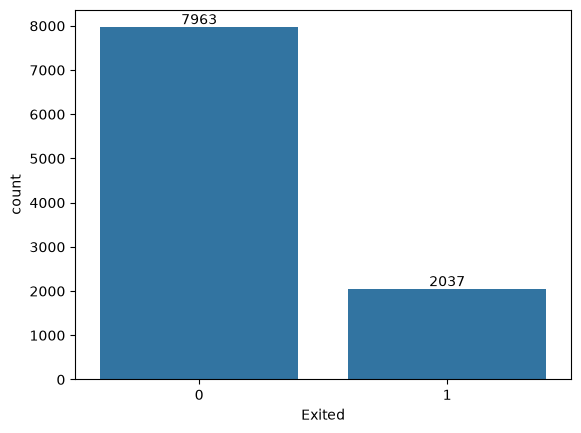

In [58]:
# Representation de la variable à prédire pour voir la proportion des occurrences
import seaborn as sns
import matplotlib.pyplot as plt

ax = sns.countplot(x='Exited', data=df)

# ajout des etiquettes
for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height())}', 
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom'
    )

plt.show()

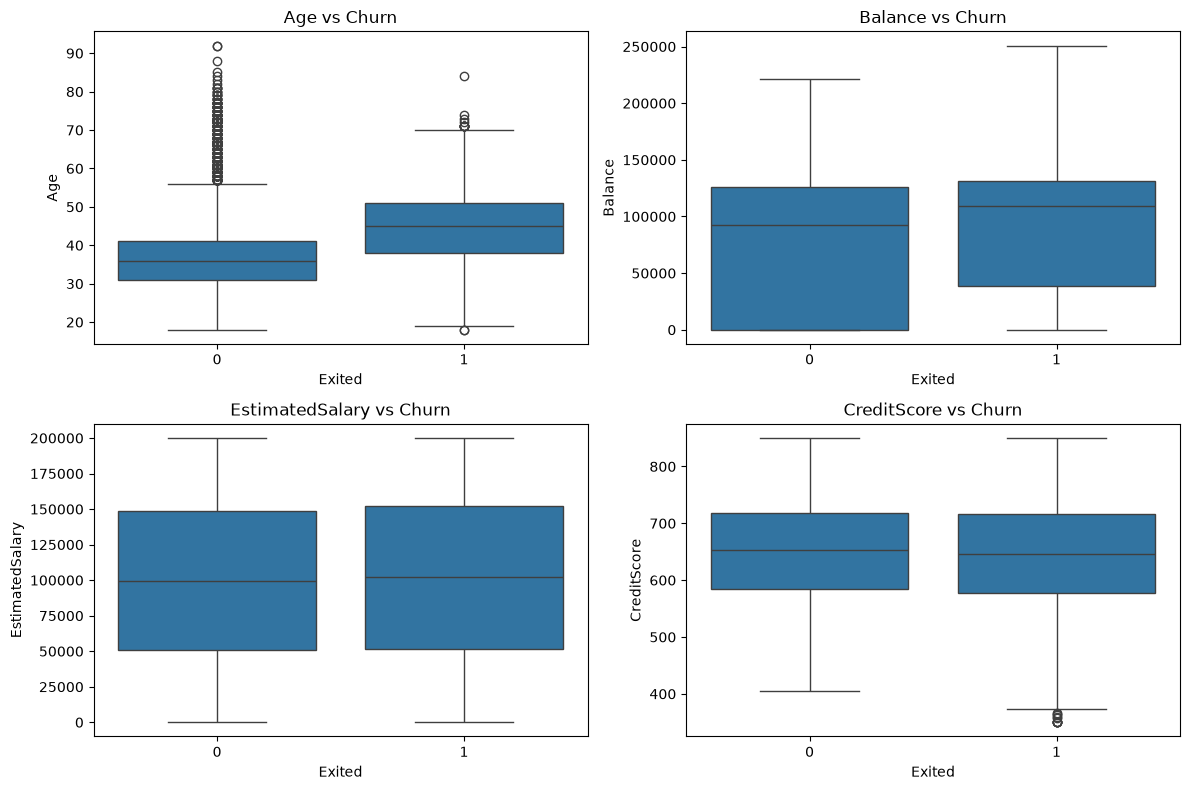

In [59]:
# analyse par boxplots
plt.figure(figsize=(12,8))

for i, var in enumerate(['Age', 'Balance', 'EstimatedSalary', 'CreditScore']):
    plt.subplot(2,2,i+1)
    sns.boxplot(x='Exited', y=var, data=df)
    plt.title(f"{var} vs Churn")

plt.tight_layout()
plt.show()

L’analyse exploratoire à travers les boxplots montre que Les clients plus âgés ont un risque de churn plus élevé 
et détiennent en moyenne un solde plus élevé. 
En revanche, le salaire et le score de crédit n’apparaissent pas comme des facteurs discriminants majeurs

In [60]:
df["Exited"].value_counts(normalize=True)

Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64

# Feature engineering: construction de nouvelles variables

In [61]:
df["BalanceSalaryRatio"] = df["Balance"] / (df["EstimatedSalary"] + 1)
df["AgeGroup"] = pd.cut(df["Age"], bins=[18,30,40,50,60,100])
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,BalanceSalaryRatio,AgeGroup
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,0.000000,"(40, 50]"
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,0.744670,"(40, 50]"
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1.401362,"(40, 50]"
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0.000000,"(30, 40]"
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,1.587035,"(40, 50]"


Quelques nettoyages

In [62]:
df = df.dropna()

Encodage

In [63]:
df = pd.get_dummies(df, drop_first=True)

Normalisation

In [64]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df.drop('Exited', axis=1))

Train / Test split

In [65]:
from sklearn.model_selection import train_test_split

X = df.drop('Exited', axis=1) # variables exogenes
y = df['Exited'] # variable endogene( target)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

# Modélisation

## Régression logistique

In [66]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

Évaluation

In [67]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.96      0.90      1600
           1       0.64      0.29      0.40       396

    accuracy                           0.83      1996
   macro avg       0.74      0.62      0.65      1996
weighted avg       0.80      0.83      0.80      1996

[[1537   63]
 [ 283  113]]


## Gérer le déséquilibre 

In [68]:
from imblearn.over_sampling import SMOTE

sm = SMOTE()
X_res, y_res = sm.fit_resample(X_train, y_train)

## Optimisation (Hyperparameters)

In [69]:
from sklearn.model_selection import GridSearchCV

params = {'C': [0.1, 1, 10]}

grid = GridSearchCV(LogisticRegression(), params, cv=5)
grid.fit(X_train, y_train)

print(grid.best_params_)

{'C': 0.1}


Interprétation : Comprendre pourquoi un client part

In [70]:
import numpy as np

coefficients = pd.DataFrame({
    "feature": X.columns,
    "importance": model.coef_[0]
}).sort_values(by="importance", ascending=False)

print(coefficients)

               feature  importance
1                  Age    0.585356
14   AgeGroup_(50, 60]    0.395827
13   AgeGroup_(40, 50]    0.390401
9    Geography_Germany    0.329201
3              Balance    0.168473
8   BalanceSalaryRatio    0.062145
7      EstimatedSalary    0.047810
12   AgeGroup_(30, 40]    0.043861
10     Geography_Spain    0.009852
5            HasCrCard   -0.019804
4        NumOfProducts   -0.060000
2               Tenure   -0.066437
0          CreditScore   -0.066463
15  AgeGroup_(60, 100]   -0.099863
11         Gender_Male   -0.273742
6       IsActiveMember   -0.482759


| Feature                | Coefficient | Interprétation                                                                                                                     |
| ---------------------- | ----------- | ---------------------------------------------------------------------------------------------------------------------------------- |
| **Age**                | 0.5918      | Plus le client est âgé → plus il risque de partir. L’âge est le facteur le plus influent.                                          |
| **AgeGroup_(50,60]**   | 0.3903      | Les clients de 50-60 ans sont plus susceptibles de churn par rapport à la référence (<30 ans).                                     |
| **AgeGroup_(40,50]**   | 0.3850      | Même logique pour 40-50 ans.                                                                                                       |
| **Geography_Germany**  | 0.3290      | Les clients allemands ont plus de risque de churn que ceux du pays de référence (probablement France).                             |
| **Balance**            | 0.1684      | Plus le solde du compte est élevé → risque de churn légèrement plus élevé. Peut indiquer que les clients riches sont plus mobiles. |
| **BalanceSalaryRatio** | 0.0694      | Ratio solde/salaire positif → léger impact sur churn.                                                                              |
| **EstimatedSalary**    | 0.0482      | Salaire plus élevé → très léger effet d’augmentation du churn.                                                                     |
| **AgeGroup_(30,40]**   | 0.0397      | Peu d’impact, mais légèrement plus de churn que référence.                                                                         |
| **Geography_Spain**    | 0.0100      | Presque neutre.                                                                                                                    |
| **HasCrCard**          | -0.0198     | Avoir une carte bancaire → très léger effet protecteur.                                                                            |
| **NumOfProducts**      | -0.0599     | Plus de produits → moins de chance de churn (fidélisation).                                                                        |
| **CreditScore**        | -0.0665     | Score élevé → client moins à risque.                                                                                               |
| **Tenure**             | -0.0665     | Ancienneté → réduit légèrement le churn.                                                                                           |
| **AgeGroup_(60,100]**  | -0.1059     | Les clients très âgés (>60) sont légèrement moins susceptibles de churn par rapport à la catégorie <30 ans.                        |
| **Gender_Male**        | -0.2738     | Les hommes ont moins tendance à churn que les femmes.                                                                              |
| **IsActiveMember**     | -0.4830     | Facteur protecteur majeur : un client actif est beaucoup moins susceptible de partir.                                              |


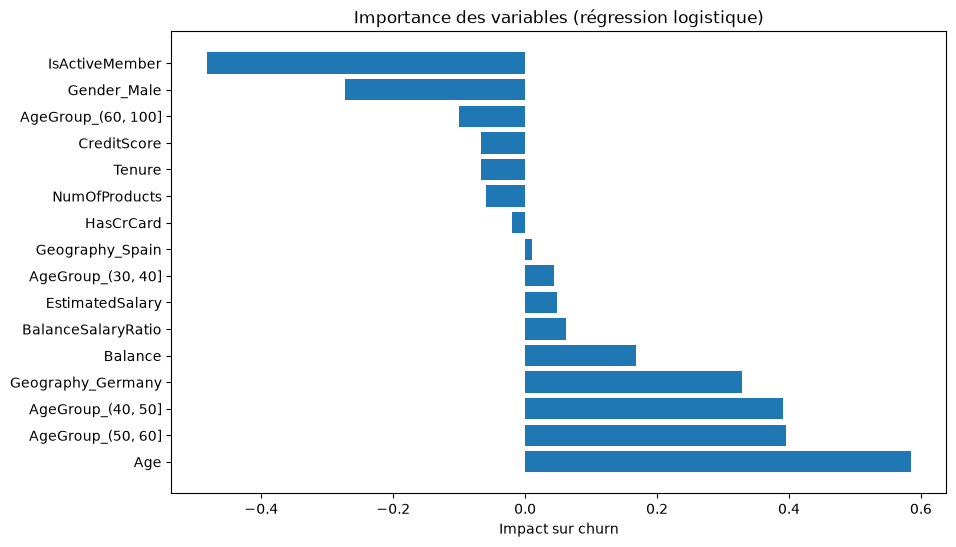

In [71]:
import matplotlib.pyplot as plt

coef_df = pd.DataFrame({
    'feature': X.columns,
    'importance': model.coef_[0]
}).sort_values(by='importance', ascending=False)

plt.figure(figsize=(10,6))
plt.barh(coef_df['feature'], coef_df['importance'])
plt.xlabel("Impact sur churn")
plt.title("Importance des variables (régression logistique)")
plt.show()

## Avec la regression logistique:
## Ce qui retient les clients (Impact Négatif sur le Churn)

Les barres vers la gauche indiquent les facteurs qui diminuent la probabilité de départ :

IsActiveMember (Le plus fort) : C'est le facteur de rétention n°1. Un client actif est beaucoup moins susceptible de partir.

Gender_Male : Les hommes semblent avoir une probabilité de départ plus faible que les femmes dans ce jeu de données.

AgeGroup (60, 100] : Étonnamment, les clients très seniors (plus de 60 ans) sont plus stables.

NumOfProducts : Plus un client possède de produits, moins il part (effet de "sticky business").

## Ce qui provoque le départ (Impact Positif sur le Churn)

Les barres vers la droite indiquent les facteurs qui augmentent la probabilité de départ :

Age (Le plus fort) : De manière générale, plus l'âge augmente, plus le risque de churn s'élève, avec des pics très marqués pour les tranches [40, 50] et [50, 60].

Geography_Germany : Être un client en Allemagne est un fort prédicteur de départ par rapport aux autres pays.

Balance : Un solde élevé est corrélé à un risque de départ plus important (ce qui est souvent contre-intuitif, mais fréquent si ces clients cherchent de meilleurs placements ailleurs).

Calcul de la ROC et AUC

In [72]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Probabilité de churn (classe 1)
y_proba = model.predict_proba(X_test)[:,1]

# Calcul FPR, TPR et seuils
fpr, tpr, thresholds = roc_curve(y_test, y_proba)

# Calcul AUC
roc_auc = auc(fpr, tpr)

In [73]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Probabilité de churn (classe 1)
y_proba = model.predict_proba(X_test)[:,1]

# Calcul FPR, TPR et seuils
fpr, tpr, thresholds = roc_curve(y_test, y_proba)

# Calcul AUC
roc_auc = auc(fpr, tpr)

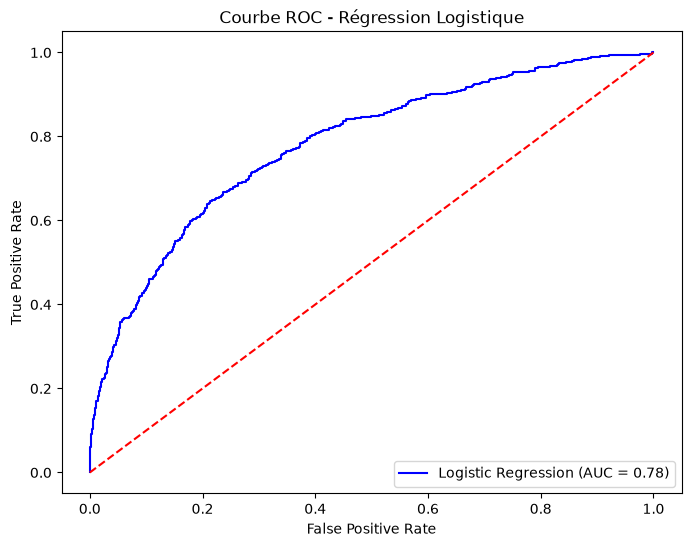

In [74]:
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, color='blue', label=f'Logistic Regression (AUC = {roc_auc:.2f})')
plt.plot([0,1], [0,1], color='red', linestyle='--')  # ligne diagonale = hasard
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Courbe ROC - Régression Logistique')
plt.legend(loc='lower right')
plt.show()

## Préprocessing avancé (propre et scalable)

In [75]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

num_cols = X.select_dtypes(include=['int64', 'float64']).columns # Les colonnes numeriques
cat_cols = X.select_dtypes(include=['object']).columns # les colonnes categorielles

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Random Forest

In [76]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline([
    ('prep', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        class_weight='balanced',
        random_state=42
    ))
])

rf_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['CreditScore','Age','Tenure',...,'AgeGroup_(40, 50]','AgeGroup_(50, 60]', 'AgeGroup_(60, 100]']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pas

## XGBoost

In [77]:
from xgboost import XGBClassifier

xgb_pipeline = Pipeline([
    ('prep', preprocessor),
    ('model', XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight= (len(y_train) / sum(y_train)),
        random_state=42
    ))
])

xgb_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['CreditScore','Age','Tenure',...,'AgeGroup_(40, 50]','AgeGroup_(50, 60]', 'AgeGroup_(60, 100]']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pas

## Évaluation 

In [78]:
from sklearn.metrics import roc_auc_score, classification_report

def evaluate(model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:,1]
    
    print(classification_report(y_test, y_pred))
    print("ROC-AUC:", roc_auc_score(y_test, y_proba))

print("Random Forest")
evaluate(rf_pipeline, X_test, y_test)

print("\nXGBoost")
evaluate(xgb_pipeline, X_test, y_test)

Random Forest
              precision    recall  f1-score   support

           0       0.91      0.83      0.87      1589
           1       0.50      0.67      0.57       407

    accuracy                           0.80      1996
   macro avg       0.71      0.75      0.72      1996
weighted avg       0.83      0.80      0.81      1996

ROC-AUC: 0.8419539741125643

XGBoost
              precision    recall  f1-score   support

           0       0.91      0.82      0.86      1589
           1       0.49      0.68      0.57       407

    accuracy                           0.79      1996
   macro avg       0.70      0.75      0.72      1996
weighted avg       0.82      0.79      0.80      1996

ROC-AUC: 0.8378517541513135


Feature importance
Random Forest

In [79]:
importances = rf_pipeline.named_steps['model'].feature_importances_

In [80]:
importances

array([0.0767322 , 0.3448832 , 0.04295706, 0.08693887, 0.22544288,
       0.01043518, 0.06254724, 0.07882329, 0.07124008])

XGBoost

In [81]:
importances = xgb_pipeline.named_steps['model'].feature_importances_
importances

array([0.05579071, 0.14751107, 0.05016622, 0.06824876, 0.34193006,
       0.04613243, 0.16605893, 0.05754484, 0.06661692], dtype=float32)

## Explicabilité avec SHAP 

C:\Users\angou\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


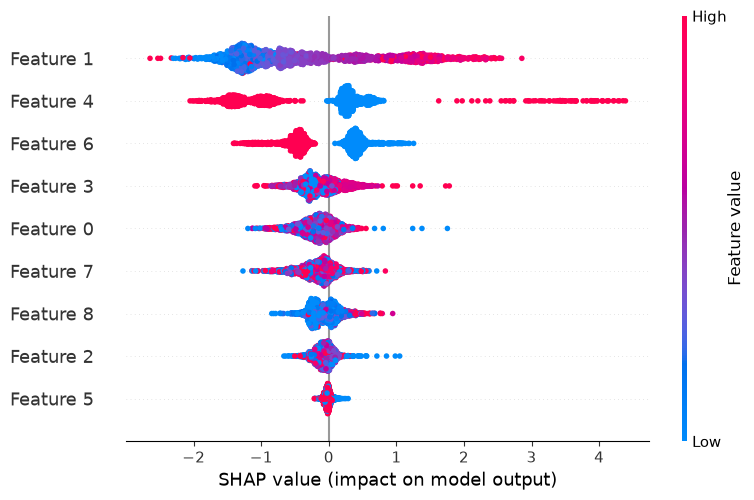

In [82]:
import shap

model = xgb_pipeline.named_steps['model']
explainer = shap.TreeExplainer(model)

X_transformed = xgb_pipeline.named_steps['prep'].transform(X_test)

shap_values = explainer.shap_values(X_transformed)

shap.summary_plot(shap_values, X_transformed)

J’utilise SHAP pour interpréter mes modèles XGBoost et Random Forest. 
Cela me permet d’identifier non seulement les variables importantes, mais aussi leur impact directionnel sur le churn. 
exemple, un âge élevé augmente la probabilité de churn, tandis que l’activité client la réduit fortement.

## Extraire l’importance des variables Pour Random Forest

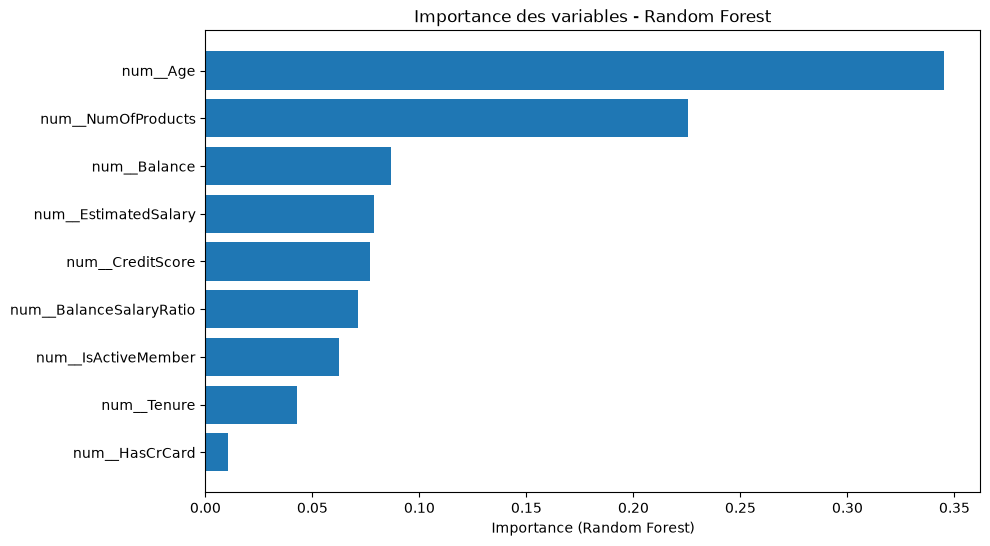

In [83]:
import pandas as pd
import matplotlib.pyplot as plt

# Extraire l'étape du modèle du pipeline
rf_model = rf_pipeline.named_steps['model']

# Récupérer les features après preprocessing
# Attention si tu as OneHotEncoder
feature_names = rf_pipeline.named_steps['prep'].get_feature_names_out()

# Importance
rf_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': rf_model.feature_importances_
}).sort_values(by='importance', ascending=False)

# Affichage
plt.figure(figsize=(10,6))
plt.barh(rf_importance['feature'], rf_importance['importance'])
plt.gca().invert_yaxis()
plt.xlabel("Importance (Random Forest)")
plt.title("Importance des variables - Random Forest")
plt.show()

## Pour XGBoost

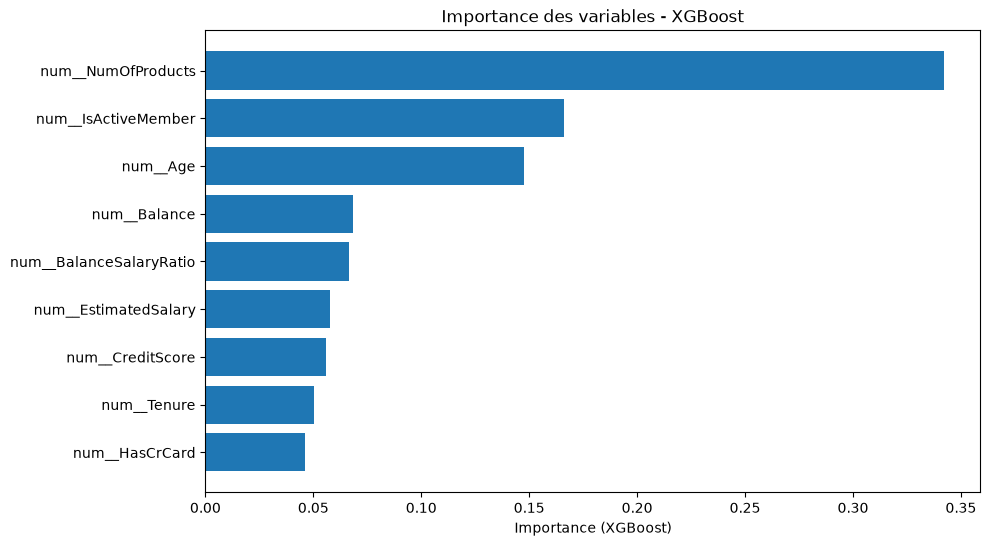

In [84]:
xgb_model = xgb_pipeline.named_steps['model']

xgb_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': xgb_model.feature_importances_
}).sort_values(by='importance', ascending=False)

plt.figure(figsize=(10,6))
plt.barh(xgb_importance['feature'], xgb_importance['importance'])
plt.gca().invert_yaxis()
plt.xlabel("Importance (XGBoost)")
plt.title("Importance des variables - XGBoost")
plt.show()

## interpretation:
Les deux modèles s'accordent sur le fait que trois variables dominent largement le pouvoir prédictif :

num__NumOfProducts (Nombre de produits) : C'est un prédicteur majeur pour les deux. Cela suggère que la fidélité est fortement liée à la profondeur de la relation bancaire.

num__Age : L'âge est un facteur clé, particulièrement crucial pour le Random Forest.

num__IsActiveMember : Le fait d'être un membre actif est déterminant, surtout pour XGBoost.
    
## Interpretation metiers
    
 Ciblez l'engagement : Le comportement (nombre de produits possédés et activité réelle du client) est le meilleur indicateur de risque ou de fidélité.

Surveillez les tranches d'âge : Il existe probablement des "âges critiques" où le comportement des clients change radicalement.

Inutile de trop se focaliser sur la carte de crédit : Que le client possède ou non une carte de crédit ne semble pas aider à prédire son comportement futur dans ce jeu de données spécifique.

## Courbe de ROC pour comparer les modèles

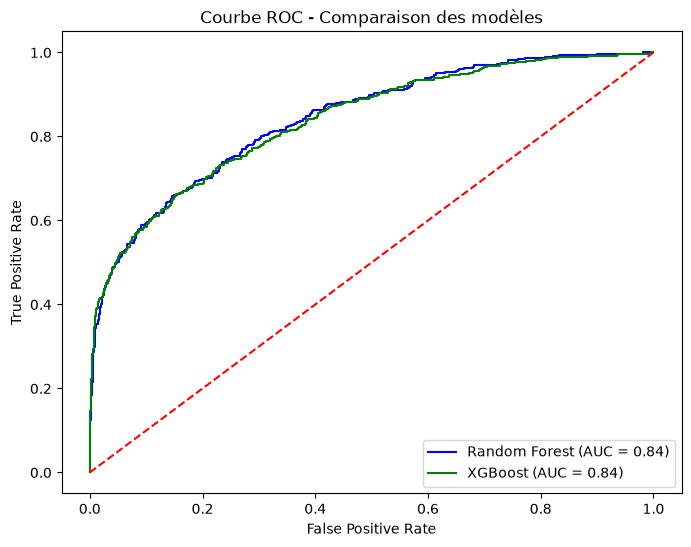

In [85]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Probabilités pour la classe positive
y_rf_proba = rf_pipeline.predict_proba(X_test)[:,1]
y_xgb_proba = xgb_pipeline.predict_proba(X_test)[:,1]

# Calcul ROC
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_rf_proba)
roc_auc_rf = auc(fpr_rf, tpr_rf)

fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_xgb_proba)
roc_auc_xgb = auc(fpr_xgb, tpr_xgb)

# Plot
plt.figure(figsize=(8,6))
plt.plot(fpr_rf, tpr_rf, color='blue', label=f'Random Forest (AUC = {roc_auc_rf:.2f})')
plt.plot(fpr_xgb, tpr_xgb, color='green', label=f'XGBoost (AUC = {roc_auc_xgb:.2f})')
plt.plot([0,1],[0,1], color='red', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Courbe ROC - Comparaison des modèles')
plt.legend(loc='lower right')
plt.show()

## Analyse globale
Pour réduire le churn, les modèles suggèrent trois leviers prioritaires :

Réactiver les membres passifs (l'impact de IsActiveMember est massif).

Cibler spécifiquement les 40-60 ans (zone de danger maximale).

Analyser le marché allemand (pour comprendre pourquoi les clients y partent plus qu'ailleurs).